# AI4I 2020 Predictive Maintenance – EDA and Model Experimentation

## Objective
The objective of this project is to predict machine failures using machine operating and sensor data.

## Dataset
AI4I 2020 Predictive Maintenance Dataset.

## Models
- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)

## Evaluation
Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

data_path = "../../task1_ml/data/ai4i2020.csv"

if not os.path.exists(data_path):
    data_path = "../data/ai4i2020.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Machine failure"].value_counts())

print("\nTarget Distribution Percentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000



Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows:
0

Target Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Target Distribution Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


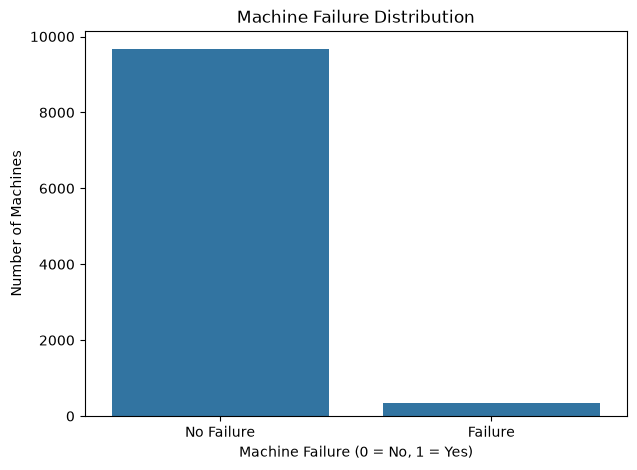

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")

plt.xticks([0, 1], ["No Failure", "Failure"])

plt.show()

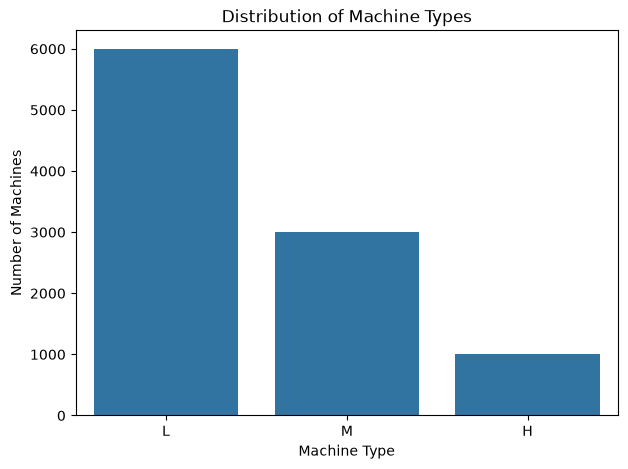

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Type",
    order=["L", "M", "H"]
)

plt.title("Distribution of Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Number of Machines")

plt.show()

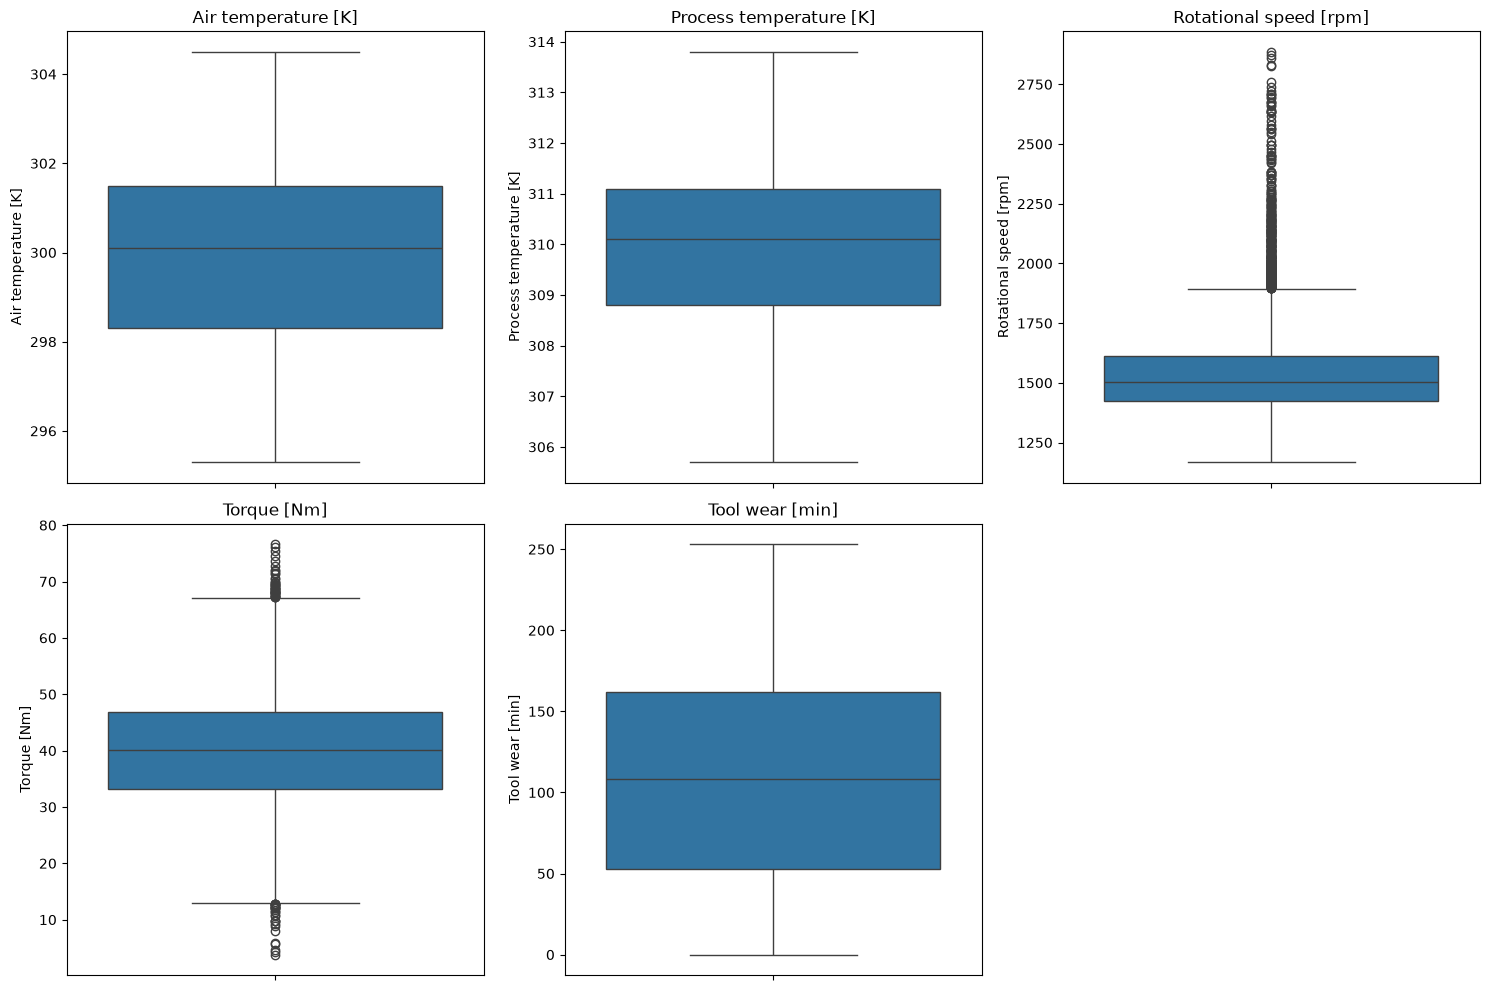

In [5]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(sensor_features):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

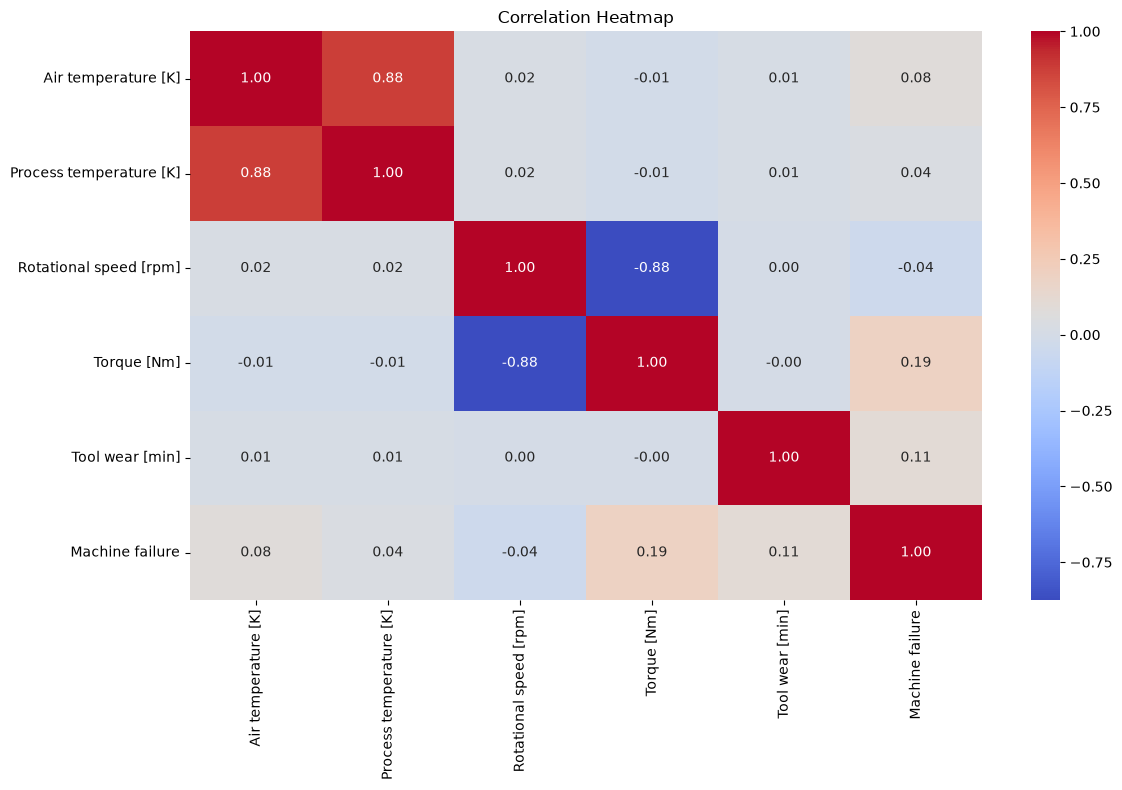


Correlation with Machine Failure:
Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64


In [6]:
plt.figure(figsize=(12, 8))

correlation = df[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure"
    ]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with Machine Failure:")
print(
    correlation["Machine failure"]
    .sort_values(ascending=False)
)

In [7]:
print("Outlier Detection using IQR\n")

for column in sensor_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(column, ":", len(outliers))

Outlier Detection using IQR

Air temperature [K] : 0
Process temperature [K] : 0
Rotational speed [rpm] : 418
Torque [Nm] : 69
Tool wear [min] : 0


In [8]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features]
y = df[target]

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(features)

Input Features:
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  

Target:
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

Input Shape: (10000, 6)
Target Shape: (10000,)

Selected Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (8000, 6)
Testing Data Shape: (2000, 6)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (8000, 8)
Processed Testing Shape: (2000, 8)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ),

    "SVM": SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

results = []

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df.round(4))

Training: Logistic Regression
Training: Random Forest
Training: SVM


D:\AI_ML_Engineer_Assessment\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070,0.3818
1,Random Forest,0.9795,0.7213,0.6471,0.6822,0.9612,0.7551
2,SVM,0.9175,0.2785,0.8971,0.4251,0.9655,0.6119


In [12]:
import joblib
from sklearn.metrics import classification_report, confusion_matrix

tuned_model = joblib.load("../models/tuned_random_forest.joblib")

tuned_predictions = tuned_model.predict(X_test_processed)
tuned_probabilities = tuned_model.predict_proba(X_test_processed)[:, 1]

print("Tuned Random Forest Results\n")

print("Accuracy:", accuracy_score(y_test, tuned_predictions))
print("Precision:", precision_score(y_test, tuned_predictions))
print("Recall:", recall_score(y_test, tuned_predictions))
print("F1 Score:", f1_score(y_test, tuned_predictions))
print("ROC-AUC:", roc_auc_score(y_test, tuned_probabilities))
print("PR-AUC:", average_precision_score(y_test, tuned_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions))

Tuned Random Forest Results

Accuracy: 0.9835
Precision: 0.9069767441860465
Recall: 0.5735294117647058
F1 Score: 0.7027027027027027
ROC-AUC: 0.9614998173182315
PR-AUC: 0.8099410483124676

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.91      0.57      0.70        68

    accuracy                           0.98      2000
   macro avg       0.95      0.79      0.85      2000
weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1928    4]
 [  29   39]]


Feature Importance:


,Feature,Importance
3,numerical__Torque [Nm],0.321401
2,numerical__Rotational speed [rpm],0.299179
4,numerical__Tool wear [min],0.212909
0,numerical__Air temperature [K],0.088485
1,numerical__Process temperature [K],0.061112
6,categorical__Type_L,0.007333
7,categorical__Type_M,0.006200
5,categorical__Type_H,0.003381


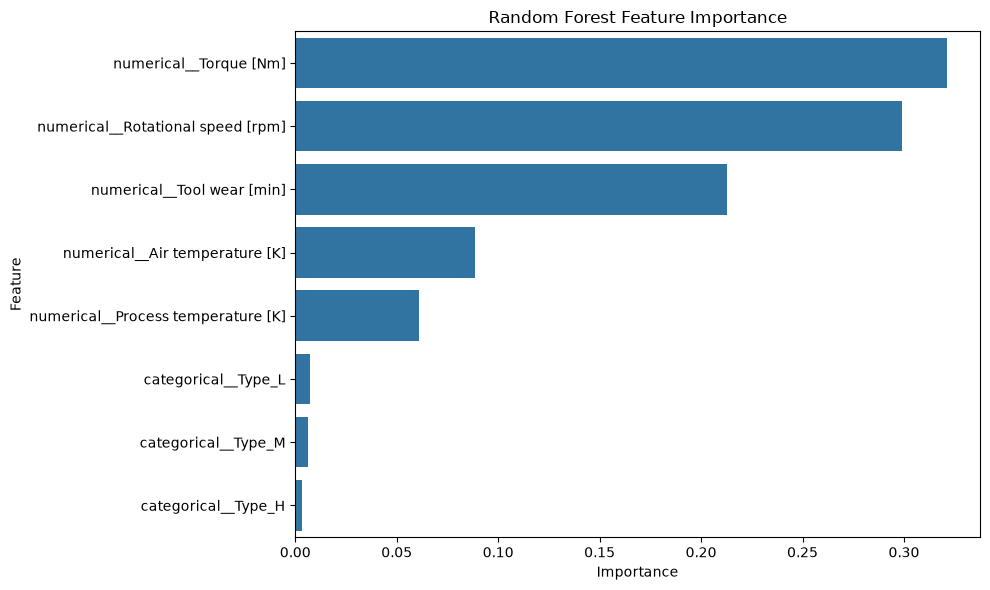

In [13]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tuned_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [14]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = tuned_predictions

error_analysis["Error Type"] = "Correct"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "Error Type"
] = "False Positive"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0),
    "Error Type"
] = "False Negative"

print("Error Analysis Summary:")
print(error_analysis["Error Type"].value_counts())

print("\nFalse Positive Examples:")
display(error_analysis[
    error_analysis["Error Type"] == "False Positive"
].head())

print("\nFalse Negative Examples:")
display(error_analysis[
    error_analysis["Error Type"] == "False Negative"
].head())

Error Analysis Summary:
Error Type
Correct           1967
False Negative      29
False Positive       4
Name: count, dtype: int64

False Positive Examples:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Actual,Predicted,Error Type
4231,L,302.2,310.8,1340,47.8,54,0,1,False Positive
3596,L,301.7,310.5,1354,50.0,169,0,1,False Positive
3794,M,302.2,310.8,1356,48.3,36,0,1,False Positive
6127,L,300.9,310.9,1228,66.4,109,0,1,False Positive



False Negative Examples:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Actual,Predicted,Error Type
4851,L,303.7,312.1,1363,51.8,90,1,0,False Negative
4632,M,302.9,311.2,1330,53.7,200,1,0,False Negative
7884,L,300.8,312.4,1465,59.1,91,1,0,False Negative
9174,L,297.8,308.9,1871,25.6,200,1,0,False Negative
3806,M,302.3,310.9,1360,44.0,67,1,0,False Negative


## Final Observations and Conclusion

1. The AI4I 2020 dataset contains 10,000 records and 14 columns.
2. No missing values or duplicate records were found.
3. The dataset is highly imbalanced, with only 3.39% machine failures.
4. Three classification algorithms were trained: Logistic Regression, Random Forest, and SVM.
5. Random Forest provided a better balance between precision and recall among the baseline models.
6. Hyperparameter tuning improved the Random Forest F1 score to 0.7027 and PR-AUC to 0.8099.
7. Torque, rotational speed, and tool wear were the three most important features.
8. Error analysis identified 4 false positives and 29 false negatives.

### Conclusion

The tuned Random Forest model achieved 98.35% accuracy and 80.99% PR-AUC. It can help identify potential machine failures using sensor measurements. However, the model missed 29 actual failures in the test set. Further improvement, particularly in recall, is required before real-world deployment.